In [1]:
"""
main.py
=======
Runner simulasi Federated Learning (Flower) + komparasi antar agregasi,
dengan opsi beberapa seed agar hasil tidak dianggap kebetulan.
 
Contoh (terminal):
    python main.py                                   # semua algoritma, seed = SEEDS di bawah
    python main.py --seeds 0 1 2 3 4                 # timpa SEEDS (opsional)
    python main.py --seeds 0 1 2 --algos fedavg fedpairwise
    python main.py --algo fedpairwise --seeds 0 1    # satu algoritma
    python main.py --info                            # ringkasan data saja
 
Di Jupyter / VS Code Interactive:
    main(['--seeds', '0', '1', '2', '3', '4'])
 
Yang divariasikan oleh seed: inisialisasi model, urutan shuffle mini-batch,
dan pemilihan client tiap ronde (bila FRACTION_FIT < 1).
Pembagian data per state TETAP (diambil dari file), jadi seed tidak
menguji variasi pembagian data.
 
Output (di folder induk OUT_DIR):
    perbandingan_per_seed.csv        hasil tiap (algoritma, seed)
    perbandingan_ringkasan.csv       rata-rata & simpangan antar seed
    perbandingan_berpasangan.csv     selisih vs baseline per seed + uji
    perbandingan_f1_per_client.csv   F1 test per state (rata-rata antar seed)
    kurva_validasi.png               F1 & AUC validasi per ronde (rata-rata +- std)
"""
import argparse
import os
import sys
import time
import traceback
from pathlib import Path
 
import numpy as np
import pandas as pd
from flwr.simulation import run_simulation
 
import config
import fl_basic4 as fl          # <- ganti jika nama file strategy/client-mu berbeda
from dataset import DROP_COLS, TARGET
from model import build_model
 
# ============================================================
# 0. KONFIGURASI RUNNER
# ============================================================
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
ALGOS = ['fedavg', 'fedprox', 'fedavgm', 'fedadam', 'fedpairwise']
BASELINE = 'fedavg'                      # pembanding untuk uji berpasangan
ORIG_OUT_DIR = Path(config.OUT_DIR)      # folder induk output = ORIG_OUT_DIR.parent
ORIG_SEED = int(config.SEED)
 
# ATUR SEED DI SINI. Tiap algoritma dijalankan sekali per seed.
#   cepat (1 run per algoritma) : SEEDS = [42]
#   bukti tidak kebetulan       : SEEDS = [0, 1, 2, 3, 4]
SEEDS = [42,22,1]
 
METRIC_COLS = ['acc', 'prec', 'rec', 'f1', 'auc',
               'f1_macro', 'f1_std_klien', 'total_MB', 'waktu_s']

2026-10-20 21:56:27,833	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:

# %%
# ============================================================
# 1. DATASET, MODUL & RINGKASAN DATA
# ============================================================
def setup_dataset():
    """Arahkan config ke folder dataset dan buang cache data lama."""
    if not CLIENT_DIR.is_dir():
        sys.exit(f"Folder dataset tidak ditemukan: {CLIENT_DIR}")
    config.CLIENT_DIR = CLIENT_DIR
    # Worker Ray membaca config.py sendiri (bukan override di atas), jadi folder
    # dikirim lewat environment variable. Dibaca oleh fl_basic3.load_data().
    os.environ['FL_CLIENT_DIR'] = str(CLIENT_DIR)
    try:                                   # pastikan tidak ada Ray lama dengan env lama
        import ray
        if ray.is_initialized():
            ray.shutdown()
    except ImportError:
        pass
    clear = getattr(fl.load_data, 'cache_clear', None)
    if clear:
        clear()
    n_item = sum(1 for _ in CLIENT_DIR.iterdir())
    print(f"Dataset : {CLIENT_DIR} ({n_item} item)")
 
 
def show_modules():
    print(f"Modul FL: {fl.__name__} ({Path(fl.__file__).name})")
    cls = getattr(fl, 'FedCosinePairwise', None)
    if cls is not None:
        print(f"Agregasi pairwise dari modul: {cls.__module__}")
 
 
def available_algos(algos):
    """Buang algoritma yang tidak dikenal oleh modul fl."""
    known = getattr(fl, 'ALGOS', algos)
    ok = [a for a in algos if a in known]
    skip = [a for a in algos if a not in ok]
    if skip:
        print(f"[lewati] tidak ada di {fl.__name__}.ALGOS: {skip}")
    return ok
 
 
def data_summary():
    clients, scaler, feature_names = fl.load_data()
    n_clients = len(clients)
    n_fitur = fl.get_in_dim()
    assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"
 
    print("=" * 50)
    print(f"Jumlah client (state) : {n_clients}")
    print(f"Daftar state          : {fl.state_list()}")
    print(f"Target                : {TARGET}")
    print(f"Kolom dibuang         : {DROP_COLS}")
    print(f"Jumlah fitur          : {n_fitur}")
    print(f"Jumlah ronde          : {config.NUM_ROUNDS}")
    print(f"Client dilatih/ronde  : "
          f"{max(1, round(config.FRACTION_FIT * n_clients))} dari {n_clients}")
    print(f"Local epochs          : {config.LOCAL_EPOCHS}")
    print("=" * 50)
    for i, nama in enumerate(feature_names, 1):
        print(f"{i:>3}. {nama}")
 
    rows = {st: {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    } for st, c in clients.items()}
 
    ringkas = pd.DataFrame(rows).T
    ringkas.index.name = 'state'
    for s in ('train', 'val', 'test'):
        ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)
 
    total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
    for s in ('train', 'val', 'test'):
        total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
    ringkas.loc['TOTAL'] = total
 
    print("\nRingkasan per client:")
    print(ringkas.to_string())
 
    total_train = sum(len(c['y_train_t']) for c in clients.values())
    print("\nscaler.n_samples_seen_ vs total train:",
          scaler.n_samples_seen_, total_train, "(harus sama)")
    return n_clients
 
 
# %%
# ============================================================
# 2. JALANKAN SATU (ALGORITMA, SEED)
# ============================================================
def run_algo(algo, seed, n_clients, out_root):
    """Simulasi FL untuk satu algoritma & seed; output ke out_root/out_<algo>_s<seed>."""
    config.SEED = seed
    os.environ['FL_SEED'] = str(seed)      # dibaca server (fl_basic3.get_seed)
    config.OUT_DIR = out_root / f'out_{algo}_s{seed}'
    config.ensure_out_dir()
    # hapus sisa run sebelumnya supaya tidak terbaca sebagai hasil run ini
    for nama in ('final_params.npz', 'ronde_log.csv'):
        (config.OUT_DIR / nama).unlink(missing_ok=True)
    print(f"\n########## {algo} | seed {seed} ##########")
    run_simulation(
        server_app=fl.make_server_app(algo),
        client_app=fl.make_client_app(),
        num_supernodes=n_clients,
        backend_config={"client_resources": {"num_cpus": 1, "num_gpus": 0.0}},
    )
 
 
def load_global_model():
    """Bangun model global dari final_params.npz di config.OUT_DIR saat ini."""
    path = config.OUT_DIR / 'final_params.npz'
    if not path.exists():
        raise FileNotFoundError(
            f"{path} tidak ada: simulasi gagal sebelum ada ronde yang selesai. "
            f"Cek {config.OUT_DIR / 'client_error.log'}")
    d = np.load(path)
    w = [d[f'arr_{i}'] for i in range(len(d.files))]
    m = build_model(fl.get_in_dim(), seed=config.SEED).to(config.DEVICE)
    fl.set_weights(m, w)
    return m
 
 
def run_single(algo, seeds, n_clients, out_root):
    try:
        for seed in seeds:
            run_algo(algo, seed, n_clients, out_root)
 
            rep, ronde = fl.bandwidth_report()
            print(ronde.round(4).to_string(index=False))
 
            model = load_global_model()
            df_test = fl.evaluate_on_clients(model, split='test')
            print(df_test.round(4).to_string())
            print(fl.summarize(df_test).round(4).to_string())
            print("Pooled:", fl.evaluate_pooled(model, split='test'))
    finally:
        config.SEED = ORIG_SEED
 

Modul FL: fl_basic4 (fl_basic4.py)
Agregasi pairwise dari modul: aggregation4
Dataset : C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients (45 item)
Jumlah client (state) : 44
Daftar state          : [1, 2, 4, 5, 8, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 22, 23, 24, 25, 26, 27, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 44, 45, 46, 48, 49, 50, 51, 53, 54, 55, 56]
Target                : _michd
Kolom dibuang         : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']
Jumlah fitur          : 69
Jumlah ronde          : 10
Client dilatih/ronde  : 44 dari 44
Local epochs          : 5
  1. sexvar
  2. _age80
  3. _educag
  4. income3
  5. veteran3
  6. children
  7. _urbstat
  8. _bmi5
  9. diabete4
 10. medcost1
 11. checkup1
 12. genhlth
 13. physhlth
 14. menthlth
 15. exerany2
 16. cvdstrk3
 17. chcscnc1
 18. chcocnc1
 19. chccopd3
 20. addepev3
 21. chckdny2
 22. havarth4
 23. diabage4
 24. deaf
 25. blind
 26. decide
 27. diffwalk
 28. diffdres
 29. diffalon
 30. _rfbing6
 31. drnka

INFO :      Starting Flower ServerApp, config: num_rounds=10, no round_timeout
INFO :      
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Evaluating initial global parameters
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 44 clients (out of 44)


[server] algoritma agregasi: fedavg | seed: 42


INFO :      aggregate_fit: received 44 results and 0 failures
INFO :      configure_evaluate: strategy sampled 44 clients (out of 44)
INFO :      aggregate_evaluate: received 44 results and 0 failures
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 44 clients (out of 44)


[ronde 01] val F1 0.4841 | AUC 0.7460 | bandwidth ronde 3.499 MB


...

[ronde 10] bobot pairwise: 16=0.025, 31=0.019, 17=0.026, 13=0.021, 45=0.022, 48=0.021, 40=0.025, 30=0.024, 51=0.021, 35=0.026, 10=0.025, 36=0.018, 38=0.026, 1=0.025, 37=0.025, 5=0.024, 26=0.021, 19=0.023, 12=0.016, 25=0.022, 46=0.025, 20=0.023, 8=0.025, 44=0.026, 53=0.014, 4=0.022, 39=0.017, 18=0.020, 22=0.025, 34=0.025, 54=0.025, 29=0.024, 24=0.015, 41=0.025, 15=0.022, 50=0.027, 33=0.024, 55=0.022, 23=0.020, 49=0.024, 56=0.026, 27=0.019, 11=0.027, 2=0.026


INFO :      aggregate_evaluate: received 44 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 10 round(s) in 65.72s
INFO :      	History (loss, distributed):
INFO :      		round 1: 0.6004191038102632
INFO :      		round 2: 0.5974486614410284
INFO :      		round 3: 0.5997319380268561
INFO :      		round 4: 0.6029339103929404
INFO :      		round 5: 0.6066553846710369
INFO :      		round 6: 0.6102093587495302
INFO :      		round 7: 0.6138615790926731
INFO :      		round 8: 0.6174988641112491
INFO :      		round 9: 0.6223100403080961
INFO :      		round 10: 0.6254869978982988
INFO :      	History (metrics, distributed, fit):
INFO :      	{'agg_weight_1': [(1, 0.029674267472704505),
INFO :      	                  (2, 0.02772860952499979),
INFO :      	                  (3, 0.027017107022899084),
INFO :      	                  (4, 0.025368417460204566),
INFO :      	                  (5, 0.02657971156084944),
INFO :      	                  (6, 0.0267152802658

[ronde 10] val F1 0.4824 | AUC 0.7443 | bandwidth ronde 3.499 MB


INFO :      	                   (8, 0.01949201601632878),
INFO :      	                   (9, 0.020461145004512713),
INFO :      	                   (10, 0.02017826035531404)],
INFO :      	 'agg_weight_19': [(1, 0.018032589715256942),
INFO :      	                   (2, 0.019837251177445524),
INFO :      	                   (3, 0.020384527695167458),
INFO :      	                   (4, 0.019970261142739823),
INFO :      	                   (5, 0.02022954952961205),
INFO :      	                   (6, 0.02085495887349652),
INFO :      	                   (7, 0.02090989901328077),
INFO :      	                   (8, 0.02335730145802005),
INFO :      	                   (9, 0.0216127919318448),
INFO :      	                   (10, 0.02273209131086591)],
INFO :      	 'agg_weight_2': [(1, 0.03582807303675244),
INFO :      	                  (2, 0.033198026817469015),
INFO :      	                  (3, 0.033478778088970866),
INFO :      	                  (4, 0.03071132953844733),
INFO :  

[selesai] fedpairwise s1: F1 test 0.4654 | AUC 0.7393 | 34.99 MB | 72.5 s

PERBANDINGAN AGREGASI  (rata-rata ± simpangan antar seed; urut F1)
             n_seed              acc             prec              rec               f1              auc         f1_macro     f1_std_klien      total_MB       waktu_s
algoritma                                                                                                                                                             
fedpairwise       3  0.6962 ± 0.0045  0.3687 ± 0.0032  0.6349 ± 0.0091  0.4664 ± 0.0010  0.7392 ± 0.0005  0.4633 ± 0.0008  0.0428 ± 0.0013  34.99 ± 0.00  72.93 ± 0.45
fedprox           3  0.6936 ± 0.0054  0.3660 ± 0.0043  0.6342 ± 0.0096  0.4641 ± 0.0026  0.7361 ± 0.0012  0.4612 ± 0.0029  0.0433 ± 0.0040  34.99 ± 0.00  91.80 ± 3.56
fedavg            3  0.6952 ± 0.0056  0.3668 ± 0.0045  0.6290 ± 0.0095  0.4633 ± 0.0024  0.7350 ± 0.0007  0.4605 ± 0.0030  0.0428 ± 0.0053  34.99 ± 0.00  70.30 ± 1.51
fedadam           3  0.

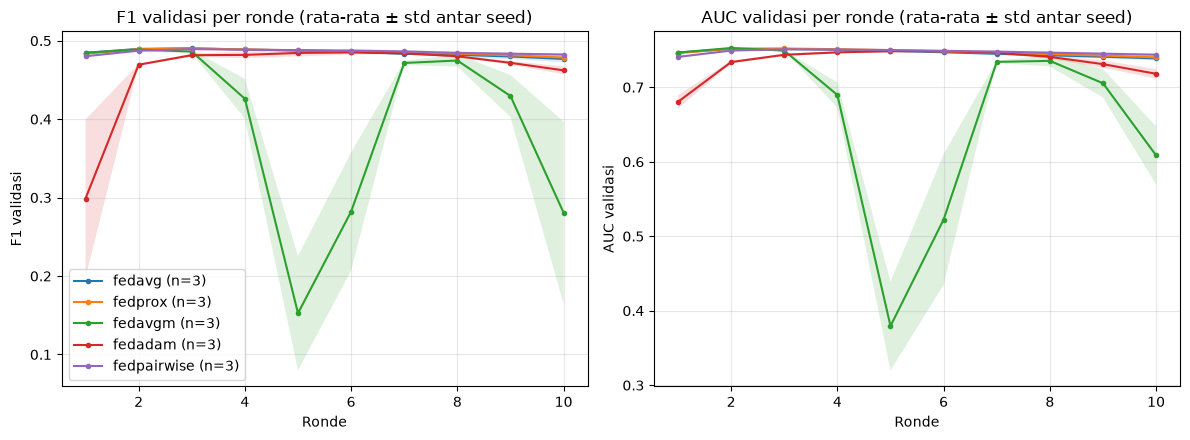

In [3]:

# %%
# ============================================================
# 3. KOMPARASI ANTAR AGREGASI (multi-seed)
# ============================================================
def collect_result(secs):
    """Kumpulkan hasil run yang baru selesai (config.OUT_DIR sudah menunjuk ke run itu)."""
    model = load_global_model()
    pooled = fl.evaluate_pooled(model, split='test')
    df_test = fl.evaluate_on_clients(model, split='test')
    ronde = pd.read_csv(config.OUT_DIR / 'ronde_log.csv')
    bw, _ = fl.bandwidth_report(verbose=False)
 
    f1 = ronde['f1'].astype(float)
    if f1.notna().any():
        best = f1.idxmax()
        val_best, best_round = float(f1[best]), int(ronde.loc[best, 'round'])
    else:
        val_best, best_round = float('nan'), -1
 
    row = {
        **{k: float(v) for k, v in pooled.items()},      # metrik test gabungan
        'f1_macro':       float(df_test['f1'].mean()),   # rata-rata antar state
        'f1_std_klien':   float(df_test['f1'].std()),    # ketimpangan antar state
        'val_f1_akhir':   float(f1.iloc[-1]),
        'val_f1_terbaik': val_best,
        'ronde_terbaik':  best_round,
        'total_MB':       float(bw['total_MB']),
        'waktu_s':        round(secs, 1),
    }
    return row, df_test['f1'], ronde
 
 
def _fmt(mean, std, n, nd=4):
    if n < 2 or pd.isna(std):
        return f"{mean:.{nd}f}"
    return f"{mean:.{nd}f} ± {std:.{nd}f}"
 
 
def summarize_seeds(per_seed):
    """Rata-rata & simpangan antar seed untuk tiap algoritma."""
    cols = [c for c in METRIC_COLS if c in per_seed.columns]
    g = per_seed.groupby(level='algoritma')[cols]
    mean, std = g.mean(), g.std()
    n = g.size().rename('n_seed')
 
    num = pd.concat({'mean': mean, 'std': std}, axis=1)
    num.columns = [f'{c}_{stat}' for stat, c in num.columns]
    num.insert(0, 'n_seed', n)
    num = num.sort_values('f1_mean', ascending=False)
 
    tampil = pd.DataFrame(index=num.index)
    tampil['n_seed'] = num['n_seed']
    for c in cols:
        nd = 2 if c in ('total_MB', 'waktu_s') else 4
        tampil[c] = [_fmt(num.loc[a, f'{c}_mean'], num.loc[a, f'{c}_std'],
                          int(num.loc[a, 'n_seed']), nd) for a in num.index]
    return num, tampil
 
 
def _pvalue(d):
    """Uji-t berpasangan (selisih d terhadap 0). NaN bila tidak bisa dihitung."""
    if len(d) < 3 or float(d.std()) == 0.0:
        return float('nan')
    try:
        from scipy import stats
    except ImportError:
        return float('nan')
    return float(stats.ttest_1samp(d, 0.0).pvalue)
 
 
def paired_vs_baseline(per_seed, baseline, metrics=('f1', 'auc')):
    """Selisih tiap algoritma terhadap baseline pada seed yang sama."""
    algos = list(per_seed.index.get_level_values('algoritma').unique())
    if baseline not in algos:
        return None
    base = per_seed.xs(baseline, level='algoritma')
    out = []
    for algo in algos:
        if algo == baseline:
            continue
        cur = per_seed.xs(algo, level='algoritma')
        seeds = base.index.intersection(cur.index)
        if len(seeds) == 0:
            continue
        row = {'algoritma': algo, 'n_seed': len(seeds)}
        for m in metrics:
            d = (cur.loc[seeds, m] - base.loc[seeds, m]).astype(float)
            row[f'd{m}_mean'] = float(d.mean())
            row[f'd{m}_std'] = float(d.std()) if len(d) > 1 else float('nan')
            row[f'{m}_menang'] = f"{int((d > 0).sum())}/{len(d)}"
            row[f'{m}_p'] = _pvalue(d)
        out.append(row)
    return pd.DataFrame(out).set_index('algoritma') if out else None
 
 
def plot_curves(kurva, out_path):
    """F1 & AUC validasi per ronde: rata-rata antar seed, pita = ± std."""
    try:
        import matplotlib
        if 'ipykernel' not in sys.modules:
            matplotlib.use('Agg')
        import matplotlib.pyplot as plt
    except ImportError:
        print("[lewati grafik] matplotlib belum terpasang (pip install matplotlib)")
        return
 
    per_algo = {}
    for (algo, _), ronde in kurva.items():
        per_algo.setdefault(algo, []).append(ronde)
 
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, col, judul in zip(axes, ('f1', 'auc'), ('F1 validasi', 'AUC validasi')):
        for algo, rs in per_algo.items():
            m = pd.concat([r.set_index('round')[col] for r in rs], axis=1)
            mu, sd = m.mean(axis=1), m.std(axis=1)
            ax.plot(mu.index, mu.values, marker='o', ms=3,
                    label=f'{algo} (n={len(rs)})')
            if len(rs) > 1:
                ax.fill_between(mu.index, (mu - sd).values, (mu + sd).values, alpha=0.15)
        ax.set_xlabel('Ronde')
        ax.set_ylabel(judul)
        ax.set_title(f'{judul} per ronde (rata-rata ± std antar seed)')
        ax.grid(alpha=0.3)
    axes[0].legend()
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    print(f"Grafik disimpan: {out_path}")
    if 'ipykernel' in sys.modules:
        plt.show()
    else:
        plt.close(fig)
 
 
def run_compare(algos, seeds, n_clients, out_root):
    rows, f1_klien, kurva = {}, {}, {}
    total_run = len(algos) * len(seeds)
    print(f"\nKomparasi: {len(algos)} algoritma x {len(seeds)} seed = {total_run} run")
    print(f"Seed: {seeds}")
 
    try:
        for seed in seeds:                 # seed di luar: hasil parsial tetap seimbang
            for algo in algos:
                t0 = time.perf_counter()
                try:
                    run_algo(algo, seed, n_clients, out_root)
                    row, f1c, ronde = collect_result(time.perf_counter() - t0)
                except Exception:
                    print(f"[GAGAL] {algo} seed {seed}:\n{traceback.format_exc()}")
                    continue
                key = (algo, seed)
                rows[key], f1_klien[key], kurva[key] = row, f1c, ronde
                print(f"[selesai] {algo} s{seed}: F1 test {row['f1']:.4f} | "
                      f"AUC {row['auc']:.4f} | {row['total_MB']:.2f} MB | "
                      f"{row['waktu_s']} s")
    finally:
        config.SEED = ORIG_SEED
 
    if not rows:
        sys.exit("Tidak ada run yang berhasil.")
 
    idx = pd.MultiIndex.from_tuples(list(rows.keys()), names=['algoritma', 'seed'])
    per_seed = pd.DataFrame(list(rows.values()), index=idx)
 
    num, tampil = summarize_seeds(per_seed)
    berpasangan = paired_vs_baseline(per_seed, BASELINE)
 
    per_klien = pd.DataFrame({
        algo: pd.concat([f1_klien[k] for k in f1_klien if k[0] == algo], axis=1).mean(axis=1)
        for algo in num.index
    })
    per_klien.loc['MAKRO'] = per_klien.mean()
 
    print("\n" + "=" * 70)
    print("PERBANDINGAN AGREGASI  (rata-rata ± simpangan antar seed; urut F1)")
    print("=" * 70)
    print(tampil.to_string())
 
    print("\nHasil per seed (F1 | AUC test gabungan):")
    print(per_seed[['f1', 'auc']].round(4).unstack('seed').to_string())
 
    if berpasangan is not None:
        print(f"\nSelisih terhadap {BASELINE} pada seed yang sama "
              f"(positif = lebih baik dari {BASELINE}):")
        print(berpasangan.round(4).to_string())
        if int(berpasangan['n_seed'].min()) < 5:
            print("Catatan: dengan <5 seed uji-t lemah; jangan terlalu bergantung "
                  "pada p-value. Lihat kolom *_menang dan konsistensi arah selisih.")
    elif len(seeds) > 1:
        print(f"\n[uji berpasangan dilewati] baseline '{BASELINE}' tidak ikut/ gagal.")
 
    print("\nF1 test per state (rata-rata antar seed):")
    print(per_klien.round(4).to_string())
 
    print(f"\nTerbaik F1 (rata-rata)    : {num['f1_mean'].idxmax()}")
    print(f"Terbaik AUC (rata-rata)   : {num['auc_mean'].idxmax()}")
    if len(seeds) > 1:
        print(f"Paling stabil antar seed  : {num['f1_std'].idxmin()} (std F1 terkecil)")
    print(f"Paling merata antar state : {num['f1_std_klien_mean'].idxmin()}")
    mb = num['total_MB_mean']
    if (mb.max() - mb.min()) > 0.01 * mb.max():      # abaikan bila praktis sama
        print(f"Bandwidth terkecil        : {mb.idxmin()}")
    else:
        print("Bandwidth                 : sama untuk semua algoritma (ukuran parameter sama)")
 
    out_root.mkdir(parents=True, exist_ok=True)
    per_seed.to_csv(out_root / 'perbandingan_per_seed.csv')
    num.to_csv(out_root / 'perbandingan_ringkasan.csv')
    per_klien.to_csv(out_root / 'perbandingan_f1_per_client.csv')
    if berpasangan is not None:
        berpasangan.to_csv(out_root / 'perbandingan_berpasangan.csv')
    print(f"\nCSV disimpan di: {out_root}")
    plot_curves(kurva, out_root / 'kurva_validasi.png')
    return per_seed, num
 
 
# %%
# ============================================================
# 4. ENTRY POINT  (guard wajib untuk Ray/multiprocessing di Windows)
# ============================================================
def main(argv=None):
    ap = argparse.ArgumentParser(description="Simulasi Federated Learning")
    ap.add_argument('--algo', default=None, choices=ALGOS,
                    help="jalankan satu algoritma saja (tanpa komparasi)")
    ap.add_argument('--compare', action='store_true',
                    help="komparasi (default bila --algo tidak diberikan)")
    ap.add_argument('--algos', nargs='+', choices=ALGOS, default=ALGOS,
                    help="daftar algoritma untuk komparasi")
    ap.add_argument('--seeds', nargs='+', type=int, default=None,
                    help="timpa SEEDS di atas, mis. --seeds 0 1 2 3 4 (opsional)")
    ap.add_argument('--info', action='store_true',
                    help="hanya tampilkan ringkasan data")
    # parse_known_args: abaikan argumen asing (mis. --f=kernel.json dari Jupyter)
    args, _ = ap.parse_known_args(argv)
 
    seeds = list(dict.fromkeys(args.seeds)) if args.seeds else list(dict.fromkeys(SEEDS))
 
    show_modules()
    setup_dataset()
    n_clients = data_summary()
    if args.info:
        return
 
    out_root = ORIG_OUT_DIR.parent
 
    if args.algo and not args.compare:
        run_single(args.algo, seeds, n_clients, out_root)
    else:
        run_compare(available_algos(args.algos), seeds, n_clients, out_root)
 
 
if __name__ == '__main__':
    main()